# CIC-IDS setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

CIC_IDS_PATH = "../data/raw/CIC-IDS-2017"

## Load the dataset

In [4]:
# 1. Find and load all CSV files in the directory
all_files = glob.glob(os.path.join(CIC_IDS_PATH, "*.csv"))
df_list = []

print(f"Found {len(all_files)} CSV files. Loading and concatenating...")
for file in all_files:
    df = pd.read_csv(file)
    df_list.append(df)

# 2. Merge them into a single dataset
df_cic = pd.concat(df_list, ignore_index=True)

# 3. Clean headers (remove leading/trailing spaces)
df_cic.columns = df_cic.columns.str.strip()

# 4. Convert to Binary Labels (0 = BENIGN, 1 = Attack)
df_cic['Binary_Label'] = df_cic['Label'].apply(lambda x: 0 if x == 'BENIGN' else 1)

# 5. Separate features and labels
X_cic = df_cic.drop(columns=['Label', 'Binary_Label'])
y_cic = df_cic['Binary_Label'].values

print(f"Total samples across all days: {df_cic.shape[0]}")
print(f"Features per sample: {X_cic.shape[1]}")
print(f"Benign: {(y_cic == 0).sum()}")
print(f"Malware/Attack: {(y_cic == 1).sum()}")

Found 6 CSV files. Loading and concatenating...
Total samples across all days: 2098367
Features per sample: 78
Benign: 1713486
Malware/Attack: 384881


## Label distribution

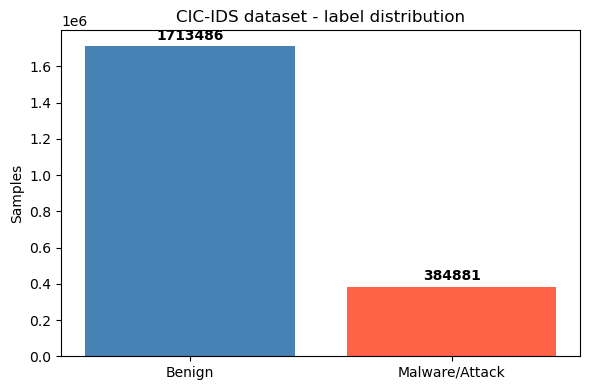

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Benign", "Malware/Attack"]

counts = [
    (y_cic == 0).sum(), 
    (y_cic == 1).sum()
]

ax.bar(labels, counts, color=["steelblue", "tomato"])
ax.set_title("CIC-IDS dataset - label distribution")
ax.set_ylabel("Samples")

# Add text labels above bars
for i, v in enumerate(counts):
    # Dynamic offset based on max count
    ax.text(i, v + (max(counts) * 0.02), str(v), ha="center", fontweight="bold") 

plt.tight_layout()
plt.savefig("../experiments/cic_label_distribution.png", dpi=150)
plt.show()

## Features statistics

In [4]:
# Taking a subset of samples to view statistics (similar to your EMBER notebook)
n_samples = 2000

print(f"Statistics on the first {n_samples} samples:\n")
print(X_cic.head(n_samples).describe().round(3))

Statistics on the first 2000 samples:

       Destination Port  Flow Duration  Total Fwd Packets  \
count          2000.000   2.000000e+03           2000.000   
mean           7153.566   1.230430e+07              8.412   
std           17648.775   3.257540e+07             30.641   
min               0.000   1.000000e+00              1.000   
25%              53.000   1.910000e+02              1.000   
50%              80.000   3.093100e+04              2.000   
75%             443.000   3.639428e+05              4.000   
max           63230.000   1.199842e+08            642.000   

       Total Backward Packets  Total Length of Fwd Packets  \
count                2000.000                     2000.000   
mean                    9.014                      528.898   
std                    42.056                     1879.926   
min                     0.000                        0.000   
25%                     1.000                       43.000   
50%                     2.000          

## Features distribution per class

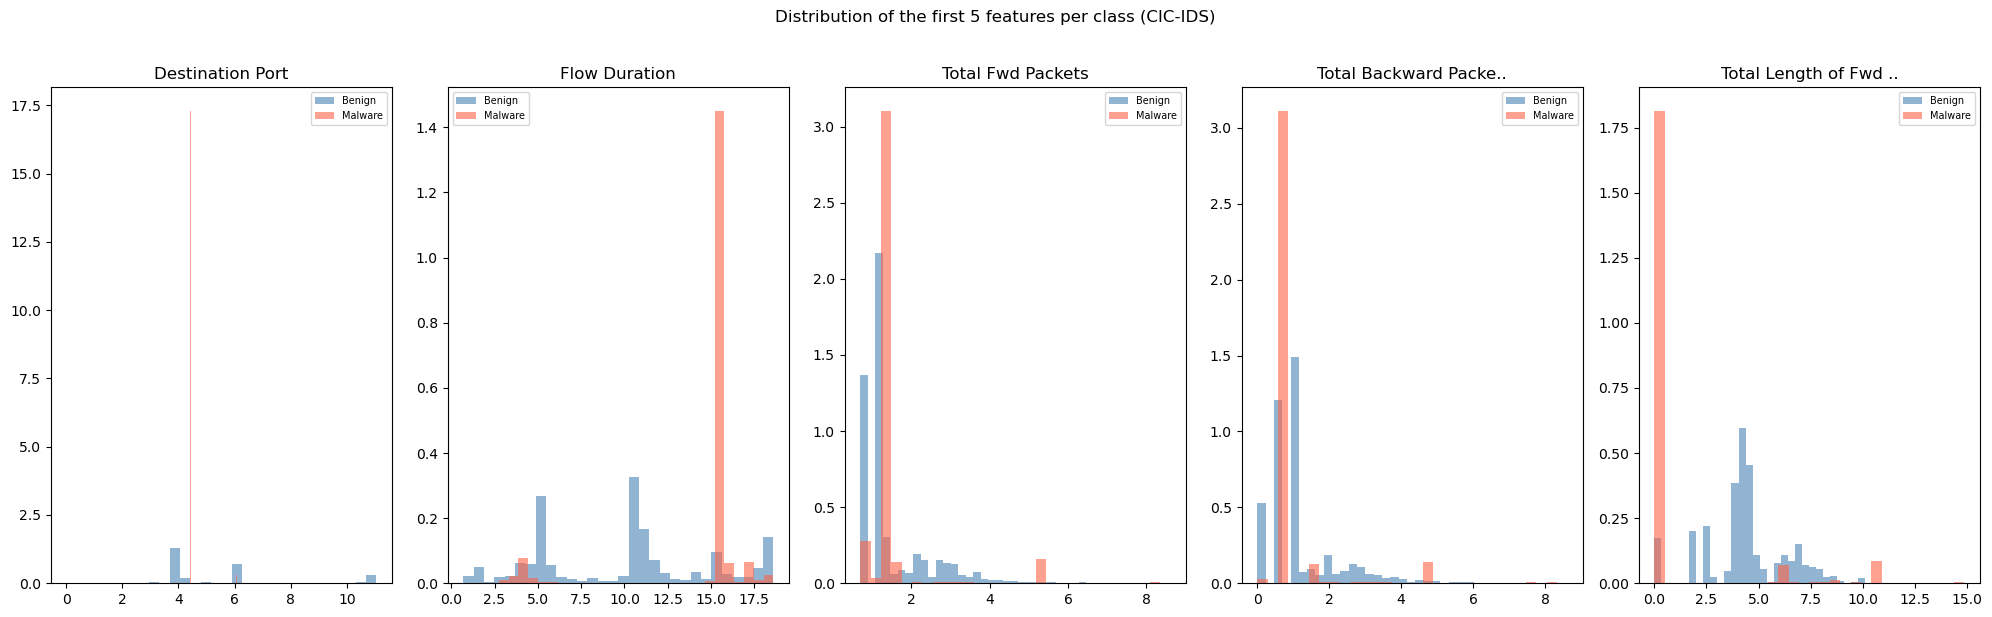

In [5]:
# compare between the first 5 features for benign and malware
n_features = 5
fig, axes = plt.subplots(1, n_features, figsize=(4 * n_features, 6))

if n_features == 1:
    axes = [axes]  # wrap it so the loop still works
axes = axes.flatten()

# Extract values and limit to first 2000 instances to speed up plotting
X_ben = X_cic[y_cic == 0].values[:2000]
X_mal = X_cic[y_cic == 1].values[:2000]

for i, ax in enumerate(axes):
    # Safely handle NaN/Inf and apply log1p (log(1 + x)) to compress extreme outliers
    ben_vals = np.log1p(np.clip(np.nan_to_num(X_ben[:, i]), a_min=0, a_max=None))
    mal_vals = np.log1p(np.clip(np.nan_to_num(X_mal[:, i]), a_min=0, a_max=None))
    
    ax.hist(ben_vals, bins=30, alpha=0.6,
            color="steelblue", label="Benign", density=True)
    ax.hist(mal_vals, bins=30, alpha=0.6,
            color="tomato", label="Malware", density=True)
    
    # Grab the actual column name for the title
    feat_name = X_cic.columns[i]
    ax.set_title(feat_name[:20] + '..' if len(feat_name) > 20 else feat_name)
    ax.legend(fontsize=7)

plt.suptitle(f"Distribution of the first {n_features} features per class (CIC-IDS)", y=1.02)
plt.tight_layout()
plt.savefig("../experiments/cic_feature_distributions.png", dpi=150)
plt.show()